# Data Exploration

In [185]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Data cleaning

In [186]:
from cleaning import cleaning

cleaning()

[PosixPath('data/clean/aportes_hidricos.csv'),
 PosixPath('data/clean/clima_colombia_diario_2000_2026.csv'),
 PosixPath('data/clean/cpc_oni_historico.csv'),
 PosixPath('data/clean/cpc_roni_historico.csv'),
 PosixPath('data/clean/demanda_comercial_reg.csv'),
 PosixPath('data/clean/demanda_real_sin.csv'),
 PosixPath('data/clean/estaciones_ideam.csv'),
 PosixPath('data/clean/generacion_real.csv'),
 PosixPath('data/clean/media_historica_aportes.csv'),
 PosixPath('data/clean/precio_bolsa_nacional.csv'),
 PosixPath('data/clean/upme_proyeccion_areas_mensual.csv'),
 PosixPath('data/clean/upme_proyeccion_sin_mensual.csv'),
 PosixPath('data/clean/volumen_util_energia_embalse.csv'),
 PosixPath('data/clean/volumen_util_energia_sistema.csv'),
 PosixPath('data/clean/all_parameters_monthly.csv'),
 PosixPath('data/clean/all_parameters_yearly.csv')]

## Data Reading

In [187]:
df_monthly = pd.read_csv("data/clean/all_parameters_monthly.csv")

df_year = pd.read_csv("data/clean/all_parameters_yearly.csv")

df_embalse = pd.read_csv("data/clean/volumen_util_energia_embalse.csv")

In [188]:
df_monthly.head(2)

,month,aportes_hidricos__Value_GWh,clima_colombia_diario_2000_2026__precipitacion_total_mm,clima_colombia_diario_2000_2026__temp_promedio_c,clima_colombia_diario_2000_2026__temp_maxima_c,cpc_oni_historico__TOTAL,cpc_oni_historico__ANOM,cpc_roni_historico__ANOM,demanda_comercial_reg__Value_GWh,demanda_real_sin__Value_GWh,generacion_real__Value_GWh,media_historica_aportes__Value_GWh,precio_bolsa_nacional__Value,upme_proyeccion_sin_mensual__demanda_sin_esc_medio_gwh,upme_proyeccion_sin_mensual__ic_sup_95_gwh,upme_proyeccion_sin_mensual__ic_inf_95_gwh,upme_proyeccion_sin_mensual__ic_sup_68_gwh,upme_proyeccion_sin_mensual__ic_inf_68_gwh,volumen_util_energia_sistema__Value_GWh
0,1950-01,NaN,NaN,NaN,NaN,25.01,-1.32,-1.19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1950-02,NaN,NaN,NaN,NaN,25.36,-1.20,-1.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [189]:
df_year.head(2)

,year,aportes_hidricos__Value_GWh,clima_colombia_diario_2000_2026__precipitacion_total_mm,clima_colombia_diario_2000_2026__temp_promedio_c,clima_colombia_diario_2000_2026__temp_maxima_c,cpc_oni_historico__TOTAL,cpc_oni_historico__ANOM,cpc_roni_historico__ANOM,demanda_comercial_reg__Value_GWh,demanda_real_sin__Value_GWh,generacion_real__Value_GWh,media_historica_aportes__Value_GWh,precio_bolsa_nacional__Value,upme_proyeccion_sin_mensual__demanda_sin_esc_medio_gwh,upme_proyeccion_sin_mensual__ic_sup_95_gwh,upme_proyeccion_sin_mensual__ic_inf_95_gwh,upme_proyeccion_sin_mensual__ic_sup_68_gwh,upme_proyeccion_sin_mensual__ic_inf_68_gwh,volumen_util_energia_sistema__Value_GWh
0,1950,NaN,NaN,NaN,NaN,25.8050,-0.878333,-0.683333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1951,NaN,NaN,NaN,NaN,27.1175,0.433333,0.635833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [190]:
df_embalse.head(2)

,Id,Name,Value_GWh,Date
0,Embalse,AGREGADO BOGOTA,1234.876797,2000-01-01
1,Embalse,ALTOANCHICAYA,29.174055,2000-01-01


In [191]:
len(df_monthly), len(df_year), len(df_embalse)

(1092, 91, 6870)

## Monthly data

In [192]:
print(df_monthly['month'].head(1))

0    1950-01
Name: month, dtype: str


In [193]:
df_monthly['year-month'] = df_monthly['month']
df_monthly[['year' , 'month']] = df_monthly['month'].str.split('-', expand=True)

In [194]:
col = df_monthly.pop('year')
df_monthly.insert(0, col.name, col)

col = df_monthly.pop('month')
df_monthly.insert(1, col.name, col)


col = df_monthly.pop('year-month')
df_monthly.insert(0, col.name, col)

In [195]:
df_monthly.head(2)

,year-month,year,month,aportes_hidricos__Value_GWh,clima_colombia_diario_2000_2026__precipitacion_total_mm,clima_colombia_diario_2000_2026__temp_promedio_c,clima_colombia_diario_2000_2026__temp_maxima_c,cpc_oni_historico__TOTAL,cpc_oni_historico__ANOM,cpc_roni_historico__ANOM,demanda_comercial_reg__Value_GWh,demanda_real_sin__Value_GWh,generacion_real__Value_GWh,media_historica_aportes__Value_GWh,precio_bolsa_nacional__Value,upme_proyeccion_sin_mensual__demanda_sin_esc_medio_gwh,upme_proyeccion_sin_mensual__ic_sup_95_gwh,upme_proyeccion_sin_mensual__ic_inf_95_gwh,upme_proyeccion_sin_mensual__ic_sup_68_gwh,upme_proyeccion_sin_mensual__ic_inf_68_gwh,volumen_util_energia_sistema__Value_GWh
0,1950-01,1950,01,NaN,NaN,NaN,NaN,25.01,-1.32,-1.19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1950-02,1950,02,NaN,NaN,NaN,NaN,25.36,-1.20,-1.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


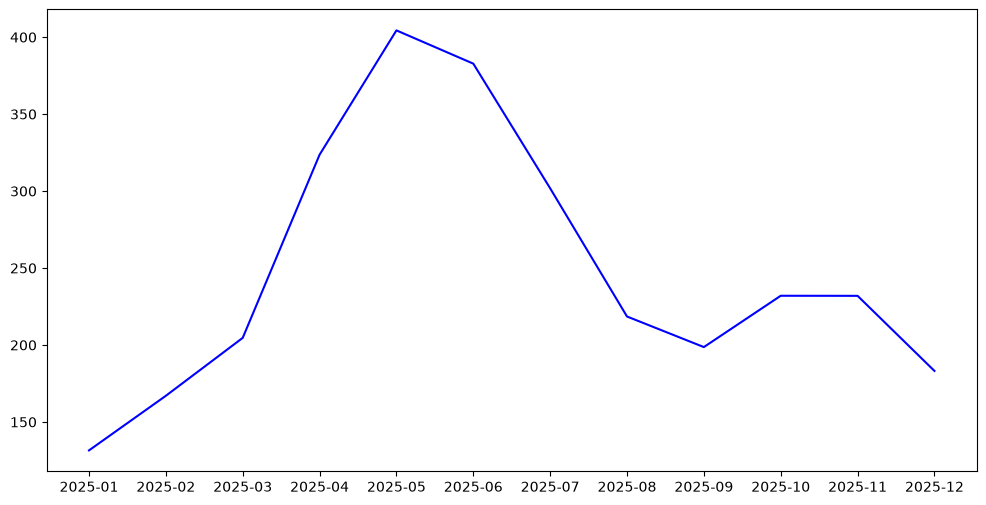

In [196]:
df_data = df_monthly[(df_monthly['year-month'] >= '2025-01') & (df_monthly['year-month'] <= '2025-12')]
plt.figure(figsize=(12, 6))
plt.plot(df_data['year-month'], df_data['aportes_hidricos__Value_GWh'], label='Aportes Hidricos', color='blue')

In [197]:
df_monthly.to_csv("data/clean/all_parameters_monthly.csv", index=False)

## Yearly data

In [198]:
print(df_monthly['year'].head(1))

0    1950
Name: year, dtype: str


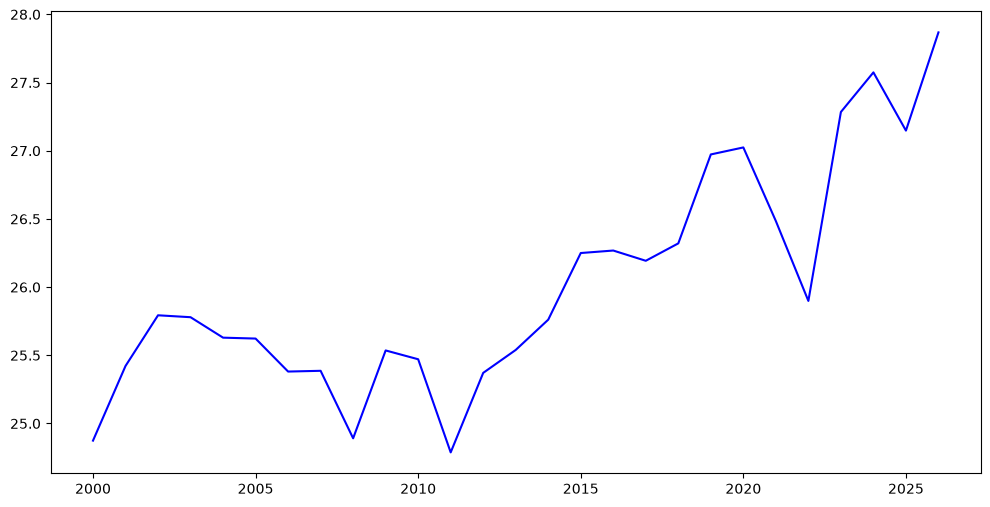

In [199]:
plt.figure(figsize=(12, 6))
plt.plot(df_year['year'], df_year['clima_colombia_diario_2000_2026__temp_maxima_c'], label='temperature', color='blue')

## Embalses data

In [200]:
df_embalse.head(2)

,Id,Name,Value_GWh,Date
0,Embalse,AGREGADO BOGOTA,1234.876797,2000-01-01
1,Embalse,ALTOANCHICAYA,29.174055,2000-01-01


In [201]:
df_embalse['year'] = pd.to_datetime(df_embalse['Date']).dt.year
df_embalse['month'] = pd.to_datetime(df_embalse['Date']).dt.month
df_embalse.head(2)

,Id,Name,Value_GWh,Date,year,month
0,Embalse,AGREGADO BOGOTA,1234.876797,2000-01-01,2000,1
1,Embalse,ALTOANCHICAYA,29.174055,2000-01-01,2000,1


In [202]:
col = df_embalse.pop('Date')
df_embalse.insert(0, col.name, col)
col = df_embalse.pop('year')
df_embalse.insert(1, col.name, col)
col = df_embalse.pop('month')
df_embalse.insert(2, col.name, col)

In [203]:
df_embalse.head(2)

,Date,year,month,Id,Name,Value_GWh
0,2000-01-01,2000,1,Embalse,AGREGADO BOGOTA,1234.876797
1,2000-01-01,2000,1,Embalse,ALTOANCHICAYA,29.174055


In [204]:
df_embalse.to_csv("data/clean/volumen_util_energia_embalse.csv", index=False)

In [205]:
df_data = df_embalse[(df_embalse['year'] >= 2024) & (df_embalse['year'] <= 2024)]
df_data = df_data.groupby(['Name']).agg({'Value_GWh': 'mean'}).reset_index()
len(df_data)

24

In [206]:
df_data = df_data.nlargest(5, 'Value_GWh')

In [207]:
df_data

,Name,Value_GWh
0,AGREGADO BOGOTA,2205.800740
12,PENOL,2113.823989
8,GUAVIO,755.514292
7,ESMERALDA,716.509752
21,TOPOCORO,616.882762


<BarContainer object of 5 artists>

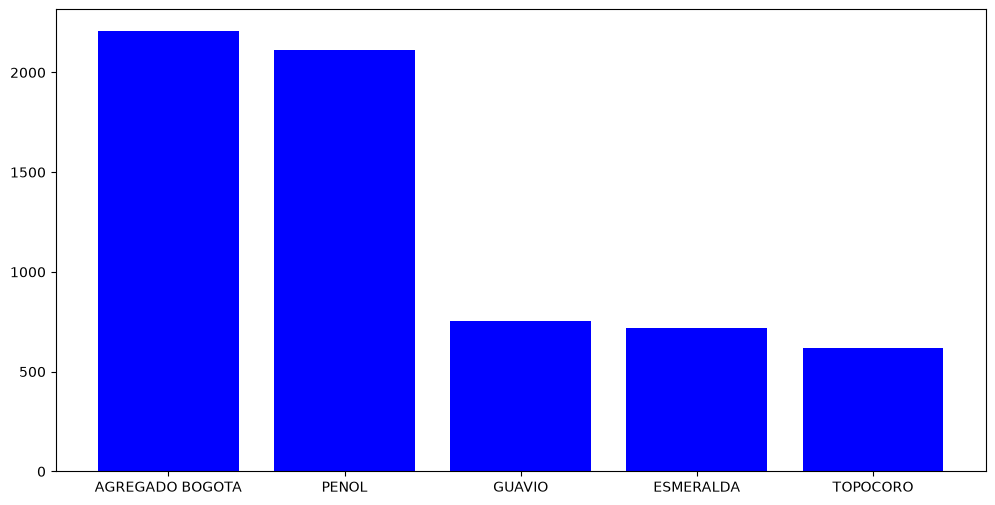

In [208]:
plt.figure(figsize=(12, 6))
plt.bar(df_data['Name'], df_data['Value_GWh'], label='Volumen Util Embalse', color='blue')

# Tabla de datos de los 3 datasets por tiempo

In [211]:
def auditar_cobertura_temporal(df, col_tiempo, nombre_dataset):
    """
    Ordena el DataFrame por la columna temporal y genera un reporte
    con la fecha exacta de inicio y fin de datos válidos para cada columna.
    """
    df_ordenado = df.sort_values(by=col_tiempo).reset_index(drop=True)
    
    resumen = []
    total_filas = len(df_ordenado)
    
    for col in df_ordenado.columns:
        if col == col_tiempo:
            continue
            
        # Encontrar el primer y último índice con dato no nulo (notna)
        primer_idx = df_ordenado[col].first_valid_index()
        ultimo_idx = df_ordenado[col].last_valid_index()
        
        if primer_idx is not None:
            fecha_inicio = df_ordenado.loc[primer_idx, col_tiempo]
            fecha_fin = df_ordenado.loc[ultimo_idx, col_tiempo]
            registros_validos = df_ordenado[col].notna().sum()
            pct_cobertura = round((registros_validos / total_filas) * 100, 1)
        else:
            fecha_inicio = "Sin datos"
            fecha_fin = "Sin datos"
            registros_validos = 0
            pct_cobertura = 0.0
            
        resumen.append({
            "Columna": col,
            "Disponible_Desde": fecha_inicio,
            "Disponible_Hasta": fecha_fin,
        })
        
    df_reporte = pd.DataFrame(resumen)
    df_reporte = df_reporte.sort_values(
        by=["Disponible_Desde", "Columna"],
        ascending=[True, True]
    ).reset_index(drop=True)
    
    print(f"\n{'='*75}")
    print(f"REPORTE DE COBERTURA TEMPORAL: {nombre_dataset}")
    print(f"Rango total de la tabla: {df_ordenado[col_tiempo].min()} a {df_ordenado[col_tiempo].max()} ({total_filas} filas)")
    print(f"{'='*75}")
    print(df_reporte.to_string(index=False))
    return df_ordenado, df_reporte

In [212]:
df_anual_ordenado, reporte_anual = auditar_cobertura_temporal(
    df=df_year, 
    col_tiempo="year", 
    nombre_dataset="DATASET ANUAL (Tabla anio)"
)

df_mensual_ordenado, reporte_mensual = auditar_cobertura_temporal(
    df=df_monthly, 
    col_tiempo="year-month", 
    nombre_dataset="DATASET MENSUAL (Tabla mes)"
)


REPORTE DE COBERTURA TEMPORAL: DATASET ANUAL (Tabla anio)
Rango total de la tabla: 1950 a 2040 (91 filas)
                                                Columna  Disponible_Desde  Disponible_Hasta
                                cpc_oni_historico__ANOM              1950              2026
                               cpc_oni_historico__TOTAL              1950              2026
                               cpc_roni_historico__ANOM              1950              2026
                            aportes_hidricos__Value_GWh              2000              2026
clima_colombia_diario_2000_2026__precipitacion_total_mm              2000              2026
         clima_colombia_diario_2000_2026__temp_maxima_c              2000              2026
       clima_colombia_diario_2000_2026__temp_promedio_c              2000              2026
                       demanda_comercial_reg__Value_GWh              2000              2026
                            demanda_real_sin__Value_GWh          